In [1]:
# Notebook 02 — Sampling, candles and moving averages
#
# Objective:
# - Build an all-hours reconstructed quote table.
# - Build a separate clock-aligned 10-second sampled table.
# - Build fixed, clock-aligned 3-minute mid-price OHLC candles.
# - Add SMA and EMA: 15, 30, 60, 100 and 200 candles.
# - Add candle-close distance from every average, in pips.
#
# Inputs:
# - Accepted observed Parquet files from etl_01_v3.
# - Existing exclusion windows and gap-bucket definitions.
# - Existing functions/etl/clean_quotes.py.
#
# Rules:
# - Real-anchor gaps <=300 seconds qualify for interpolation.
# - Synthetic points remain A+10 seconds, A+20 seconds, etc.
# - Synthetic points become available at B.
# - Entirely interpolated candles are eligible.
# - Gaps >300 seconds remain unfilled.
# - Moving averages use all hours and preserve history across breaks.
# - Empty intervals do not advance moving averages.
# - Locked quotes and zero sizes remain available for this analysis.
# - Moving averages use mid-price closes, never sizes.
#
# Units:
# - Prices and averages: USD per EUR.
# - Distances and spread_pips: EURUSD pips; one pip = 0.0001.
# - Displayed sizes: millions of EUR, confirmed by Raymond.
# - Stored timestamps: UTC Unix nanoseconds.
# - Research display: Europe/Athens.
#
# Timing:
# - Candle windows include their start and exclude their end.
# - Publication may occur after the candle closes.
# - A conservative publication rule also resolves the trailing gap.
# - Indicators inherit all required availability delays.
# - Sampled values describe the final reconstructed historical series.
#
# Scope:
# - All-hours prices construct the candle and moving-average history.
# - Existing project exclusions remain separate flags.
# - Candles overlapping an exclusion or long gap are flagged.
# - Those flags do not remove their available closes from MA history.
# - The final unfinished candle is not used for moving averages.
#
# Outputs:
# - data/processed/<RUN_ID>/quotes/
# - data/processed/<RUN_ID>/sampled_10s/
# - data/processed/<RUN_ID>/candles_3min/
# - data/processed/<RUN_ID>/long_gaps/
# - reports/tables/sampling/<RUN_ID>/
# - reports/figures/sampling/<RUN_ID>/
#
# Interpolation describes an assumed path between real observations.
# Keep its flags when designing volatility, entropy and later features.

In [2]:
# Settings and environment.
# Keep the first run limited to January 2016.
# Later, change STOP_AFTER_MONTH to a later month or None.
# Changing only STOP_AFTER_MONTH does not invalidate completed months.

from pathlib import Path
import sys
import json
import hashlib
import importlib
import importlib.util
import importlib.metadata
import time

STARTED = time.perf_counter()

ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (
        (candidate / "data").is_dir()
        and (candidate / "notebooks").is_dir()
        and (candidate / "functions" / "etl" / "clean_quotes.py").is_file()
    ):
        ROOT = candidate.resolve()
        break

assert ROOT is not None, (
    "Open this notebook from the repository's notebooks folder."
)

RUN_ID = "sampling_02_v1"
ETL_RUN_ID = "etl_01_v3"

STOP_AFTER_MONTH = "2016-01"   # None means the full available history.
DUCKDB_MEMORY_LIMIT = "2GB"
DUCKDB_THREADS = 2
DUCKDB_SPILL_LIMIT = "20GB"

EXPECTED_ETL_FINGERPRINT = (
    "205fc8b3f2417d6bcbff97a34f49215ca1cc5f2b89c626eed6a26cec65231902"
)

required_packages = ["numpy", "pandas", "pyarrow", "duckdb", "matplotlib"]
missing = [
    name for name in required_packages
    if importlib.util.find_spec(name) is None
]
assert not missing, f"Missing libraries in this Jupyter kernel: {missing}"

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import duckdb
import matplotlib.pyplot as plt

from IPython.display import display

sys.path.insert(0, str(ROOT))
from functions.etl import clean_quotes as fx

ETL = ROOT / "data" / "processed" / ETL_RUN_ID
ETL_REPORTS = ROOT / "reports" / "tables" / "etl" / ETL_RUN_ID

RUN = ROOT / "data" / "processed" / RUN_ID
TABLES = ROOT / "reports" / "tables" / "sampling" / RUN_ID
FIGURES = ROOT / "reports" / "figures" / "sampling" / RUN_ID
HELPER = ROOT / "functions" / "sampling" / "market_series.py"

assert RUN_ID and Path(RUN_ID).name == RUN_ID
assert RUN_ID != ETL_RUN_ID
assert RUN.resolve().is_relative_to(ROOT / "data" / "processed")

VERSIONS = {
    "python": sys.version.split()[0],
    **{
        name: importlib.metadata.version(name)
        for name in required_packages
    },
}

display(pd.Series(VERSIONS, name="version"))
print("Repository:", ROOT)
print("Processing target:", STOP_AFTER_MONTH or "full history")

python        3.14.8
numpy          2.5.4
pandas         3.0.6
pyarrow       26.0.0
duckdb         2.0.0
matplotlib    3.11.2
Name: version, dtype: str

Repository: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator
Processing target: 2016-01


In [3]:
# Helper source, part 1: shared operations.
# The helper file is written in Cell 7.

COMMON_CODE = r'''
import json
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import duckdb

from functions.etl import clean_quotes as fx

NS = 1_000_000_000
STEP = 10 * NS
BAR = 180 * NS
LIMIT = 300 * NS
PIP = 0.0001
WINDOWS = (15, 30, 60, 100, 200)


def frame(con, query):
    # Preserve nullable integer nanoseconds without float conversion.
    return con.sql(query).to_arrow_table().to_pandas(
        types_mapper=pd.ArrowDtype
    )


def ddl(con, query):
    con.execute(query)
    con.complete()


def save_frame(data, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.stem + ".partial.parquet")
    pq.write_table(
        pa.Table.from_pandas(data, preserve_index=False),
        temporary,
        compression="zstd",
    )
    temporary.replace(path)
    fx.verify_parquet(path, len(data))


def file_info(path):
    path = Path(path)
    stat = path.stat()
    return {
        "path": str(path),
        "bytes": stat.st_size,
        "mtime_ns": stat.st_mtime_ns,
        "rows": pq.ParquetFile(path).metadata.num_rows,
    }


def overlap_flags(starts, ends, intervals):
    starts = np.asarray(starts, dtype=np.int64)
    ends = np.asarray(ends, dtype=np.int64)
    if not intervals:
        return np.zeros(len(starts), dtype=bool)

    intervals = np.asarray(intervals, dtype=np.int64)
    index = np.searchsorted(intervals[:, 1], starts, side="right")
    safe = np.minimum(index, len(intervals) - 1)
    return (
        (index < len(intervals))
        & (intervals[safe, 0] < ends)
    )


def initial_state():
    return {
        "valid_candles": 0,
        "tail_closes": [],
        "ema_values": {str(n): None for n in WINDOWS},
        "dependency_available_ns": None,
        "last_candle_end_ns": None,
    }


def display_times(data, columns):
    result = data.copy()
    for column in columns:
        if column in result:
            result[column.replace("_ns", "_athens")] = (
                pd.to_datetime(
                    result[column].astype("Int64"),
                    unit="ns",
                    utc=True,
                ).dt.tz_convert("Europe/Athens")
            )
    return result


def write_section(path, marker, body):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    text = path.read_text(encoding="utf-8") if path.exists() else ""
    start = f"<!-- {marker}:start -->"
    end = f"<!-- {marker}:end -->"
    replacement = start + "\n" + body.strip() + "\n" + end

    if start in text:
        assert end in text, f"Unfinished documentation marker: {path}"
        left = text.index(start)
        right = text.index(end, left) + len(end)
        text = text[:left] + replacement + text[right:]
    else:
        text = text.rstrip() + "\n\n" + replacement

    path.write_text(text.strip() + "\n", encoding="utf-8")


def fixture_rows(times, bids):
    times = [int(value) for value in times]
    bids = np.asarray(bids, dtype=float)
    gaps = [None] + [
        times[i] - times[i - 1] for i in range(1, len(times))
    ]
    segments = np.cumsum([
        0 if gap is None else int(gap > LIMIT) for gap in gaps
    ]).astype(np.int64)

    return pa.table({
        "ts_ns": pa.array(times, type=pa.int64()),
        "bid": bids,
        "ask": bids + 0.0001,
        "bid_size": np.ones(len(times)),
        "ask_size": np.ones(len(times)),
        "source_copies": np.ones(len(times), dtype=np.int64),
        "representative_source_id": np.zeros(len(times), dtype=np.int64),
        "representative_source_record": np.arange(
            1, len(times) + 1, dtype=np.int64
        ),
        "a_ns": pa.array([None] + times[:-1], type=pa.int64()),
        "gap_ns": pa.array(gaps, type=pa.int64()),
        "data_segment_id": segments,
    })


def fixture_meta(table, path, label):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    pq.write_table(table, path)
    rows = table.to_pylist()
    return {
        "path": str(path),
        "year_month": label,
        "observed_rows": len(rows),
        "first": rows[0],
        "last": rows[-1],
    }
'''

In [4]:
# Helper source, part 2: all-hours quotes, sampling and candles.

MARKET_CODE = r'''
def reconstruct(con, meta, previous, following, root, previous_point, exclusions):
    root = Path(root)
    work = root / "_work"
    work.mkdir(parents=True, exist_ok=True)

    previous_analysis = None
    if previous_point is not None:
        previous_analysis = {
            key: previous_point[key]
            for key in ("ts_ns", "data_segment_id", "scope_id")
        }

    result = fx.analysis_month(
        con=con,
        meta=meta,
        previous=previous,
        following=following,
        windows=[],
        destination=work / "base.parquet",
        expected_path=work / "expected_keys.parquet",
        previous_analysis=previous_analysis,
        rebuild=True,
    )

    con.register("project_calendar", pa.table({
        "start_ns": pa.array(
            [int(x[0]) for x in exclusions], type=pa.int64()
        ),
        "end_ns": pa.array(
            [int(x[1]) for x in exclusions], type=pa.int64()
        ),
    }))

    destination = root / "quotes" / f"{meta['year_month']}.parquet"
    fx.write_query(con, """
        SELECT q.*,
            (q.bid + q.ask) / 2.0 AS mid,
            q.ask - q.bid AS spread,
            (q.ask - q.bid) / 0.0001 AS spread_pips,
            (
                e.end_ns IS NOT NULL AND q.ts_ns < e.end_ns
            ) AS project_excluded
        FROM actual_quotes q
        ASOF LEFT JOIN project_calendar e
            ON q.ts_ns >= e.start_ns
        ORDER BY q.ts_ns
    """, destination)

    con.read_parquet(
        str(destination), hive_partitioning=False
    ).create_view("points", replace=True)

    con.register("point_boundary", pa.Table.from_pylist(
        [] if previous_point is None else [previous_point],
        schema=pq.read_schema(destination),
    ))
    ddl(con, """
        CREATE OR REPLACE TEMP VIEW point_context AS
        SELECT * FROM points
        UNION ALL
        SELECT * FROM point_boundary
    """)
    ddl(con, """
        CREATE OR REPLACE TEMP VIEW real_links AS
        SELECT
            ts_ns AS a_ns,
            lead(ts_ns) OVER (ORDER BY ts_ns) AS b_ns
        FROM pairs_quotes
    """)

    last_point = fx.record(
        con, "SELECT * FROM points ORDER BY ts_ns DESC LIMIT 1"
    )
    assert result["retained_real_rows"] == meta["observed_rows"]
    fx.verify_parquet(destination, result["analysis_rows"])

    return result, last_point, destination


def derive_tables(con, meta, exclusions, first_ns, last_ns):
    lower, upper = fx.month_bounds(meta["year_month"])

    grid_start = max(lower, ((first_ns + STEP - 1) // STEP) * STEP)
    grid_stop = min(upper, (last_ns // STEP) * STEP + STEP)

    grid = frame(con, f"""
        WITH looked AS (
            SELECT
                g.sample_ns,
                q.ts_ns AS source_ns,
                q.available_ns AS source_available_ns,
                q.is_interpolated,
                q.left_anchor_ns,
                q.right_anchor_ns,
                q.bid, q.ask, q.mid, q.spread,
                q.bid_size, q.ask_size,
                r.a_ns, r.b_ns
            FROM range({grid_start}, {grid_stop}, {STEP}) g(sample_ns)
            ASOF LEFT JOIN point_context q
                ON g.sample_ns >= q.ts_ns
            ASOF LEFT JOIN real_links r
                ON g.sample_ns >= r.a_ns
        ),
        classified AS (
            SELECT *,
                coalesce(
                    sample_ns > a_ns AND b_ns - a_ns > {LIMIT},
                    false
                ) AS in_long_gap,
                CASE
                    WHEN sample_ns = a_ns THEN sample_ns
                    ELSE least(
                        coalesce(b_ns, a_ns + {LIMIT} + 1),
                        a_ns + {LIMIT} + 1
                    )
                END AS status_available_ns
            FROM looked
        ),
        valid AS (
            SELECT *,
                (
                    source_ns IS NOT NULL
                    AND NOT in_long_gap
                    AND sample_ns - source_ns >= 0
                    AND sample_ns - source_ns < {STEP}
                ) AS has_price
            FROM classified
        )
        SELECT
            sample_ns,
            has_price,
            in_long_gap,
            greatest(
                sample_ns,
                coalesce(source_available_ns, sample_ns),
                coalesce(status_available_ns, sample_ns)
            ) AS available_ns,
            status_available_ns,
            CASE WHEN has_price THEN source_ns END AS source_ts_ns,
            CASE WHEN has_price THEN source_available_ns END
                AS source_available_ns,
            CASE WHEN has_price THEN sample_ns - source_ns END
                AS source_age_ns,
            CASE WHEN has_price THEN is_interpolated END
                AS is_interpolated,
            CASE WHEN has_price THEN left_anchor_ns END AS left_anchor_ns,
            CASE WHEN has_price THEN right_anchor_ns END AS right_anchor_ns,
            CASE WHEN has_price THEN bid END AS bid,
            CASE WHEN has_price THEN ask END AS ask,
            CASE WHEN has_price THEN mid END AS mid,
            CASE WHEN has_price THEN spread END AS spread,
            CASE WHEN has_price THEN bid_size END AS bid_size,
            CASE WHEN has_price THEN ask_size END AS ask_size
        FROM valid
        ORDER BY sample_ns
    """)

    allowed, _ = fx.allowed_and_scope(
        grid["sample_ns"].to_numpy(dtype=np.int64), exclusions
    )
    grid["project_excluded"] = ~allowed
    grid["project_eligible"] = (
        grid["has_price"].to_numpy(dtype=bool) & allowed
    )

    bar_start = max(lower, (first_ns // BAR) * BAR)
    bar_stop = min(upper, (last_ns // BAR) * BAR + BAR)

    candles = frame(con, f"""
        WITH aggregated AS (
            SELECT
                (ts_ns // {BAR}) * {BAR} AS candle_start_ns,
                arg_min(mid, ts_ns) AS open_mid,
                max(mid) AS high_mid,
                min(mid) AS low_mid,
                arg_max(mid, ts_ns) AS close_mid,
                count(*)::BIGINT AS n_points,
                count(*) FILTER (WHERE NOT is_interpolated)::BIGINT AS n_real,
                count(*) FILTER (WHERE is_interpolated)::BIGINT AS n_synthetic,
                max(available_ns) AS points_available_ns
            FROM points
            GROUP BY 1
        ),
        clock AS (
            SELECT
                candle_start_ns,
                candle_start_ns + {BAR} AS candle_end_ns
            FROM range({bar_start}, {bar_stop}, {BAR}) t(candle_start_ns)
        )
        SELECT
            c.candle_start_ns,
            c.candle_end_ns,
            a.open_mid, a.high_mid, a.low_mid, a.close_mid,
            coalesce(a.n_points, 0)::BIGINT AS n_points,
            coalesce(a.n_real, 0)::BIGINT AS n_real,
            coalesce(a.n_synthetic, 0)::BIGINT AS n_synthetic,
            a.points_available_ns,
            c.candle_end_ns <= {last_ns} AS completed,
            c.candle_start_ns < {first_ns} AS left_coverage_boundary,
            CASE WHEN c.candle_end_ns <= {last_ns} THEN
                greatest(
                    c.candle_end_ns,
                    coalesce(a.points_available_ns, c.candle_end_ns),
                    coalesce(
                        least(
                            coalesce(r.b_ns, r.a_ns + {LIMIT} + 1),
                            r.a_ns + {LIMIT} + 1
                        ),
                        c.candle_end_ns
                    )
                )
            END AS available_ns
        FROM clock c
        LEFT JOIN aggregated a USING (candle_start_ns)
        ASOF LEFT JOIN real_links r
            ON c.candle_end_ns - 1 >= r.a_ns
        ORDER BY c.candle_start_ns
    """)

    long_context = frame(con, f"""
        SELECT
            left_ns AS a_ns,
            ts_ns AS b_ns,
            ts_ns - left_ns AS gap_ns,
            left_ns + {LIMIT} + 1 AS status_known_ns,
            ts_ns AS interval_available_ns
        FROM pairs_quotes
        WHERE ts_ns - left_ns > {LIMIT}
          AND left_ns < {upper}
          AND ts_ns > {lower}
        ORDER BY left_ns
    """)

    intervals = [
        [int(a), int(b)]
        for a, b in zip(long_context["a_ns"], long_context["b_ns"])
    ]
    starts = candles["candle_start_ns"].to_numpy(dtype=np.int64)
    ends = candles["candle_end_ns"].to_numpy(dtype=np.int64)

    candles["excluded_time_overlap"] = overlap_flags(
        starts, ends, exclusions
    )
    candles["long_gap_overlap"] = overlap_flags(
        starts, ends, intervals
    )
    populated = candles["n_points"].to_numpy(dtype=np.int64) > 0
    completed = candles["completed"].to_numpy(dtype=bool)

    candles["synthetic_only"] = (
        populated
        & (candles["n_real"].to_numpy(dtype=np.int64) == 0)
    )
    candles["ma_eligible"] = populated & completed
    candles["project_eligible"] = (
        populated
        & completed
        & ~candles["excluded_time_overlap"].to_numpy(dtype=bool)
        & ~candles["long_gap_overlap"].to_numpy(dtype=bool)
        & ~candles["left_coverage_boundary"].to_numpy(dtype=bool)
    )

    counts = candles["n_points"].to_numpy(dtype=np.int64)
    synthetic = candles["n_synthetic"].to_numpy(dtype=np.int64)
    candles["synthetic_fraction"] = np.divide(
        synthetic,
        counts,
        out=np.full(len(candles), np.nan),
        where=counts > 0,
    )

    owned_gaps = long_context.loc[
        (long_context["b_ns"] >= lower)
        & (long_context["b_ns"] < upper)
    ].reset_index(drop=True)

    return grid, candles, owned_gaps
'''

In [5]:
# Helper source, part 3: moving averages.
# State is small and continues across processing months and market breaks.

MA_CODE = r'''
def add_averages(candles, state):
    out = candles.copy()
    before = int(state["valid_candles"])
    tail = np.asarray(state["tail_closes"], dtype=float)
    assert len(tail) == min(before, 199)

    if out.empty:
        for n in WINDOWS:
            for column in (
                f"sma_{n}", f"ema_{n}",
                f"close_minus_sma_{n}_pips",
                f"close_minus_ema_{n}_pips",
            ):
                out[column] = pd.Series(index=out.index, dtype=float)
        out["ma_available_ns"] = pd.Series(index=out.index, dtype="Int64")
        out["valid_candle_number"] = pd.Series(index=out.index, dtype="Int64")
        return out, {
            **state,
            "tail_closes": list(state["tail_closes"]),
            "ema_values": dict(state["ema_values"]),
        }

    close = out["close_mid"].to_numpy(dtype=float)
    ends = out["candle_end_ns"].to_numpy(dtype=np.int64)
    availability = out["available_ns"].to_numpy(dtype=np.int64)

    assert np.isfinite(close).all() and (close > 0).all()
    assert (np.diff(ends) > 0).all()
    assert (availability >= ends).all()
    if state["last_candle_end_ns"] is not None:
        assert int(ends[0]) > state["last_candle_end_ns"]

    history = np.concatenate((tail, close))
    series = pd.Series(history, copy=False)
    counts = before + np.arange(1, len(close) + 1, dtype=np.int64)
    ema_after = {}

    for n in WINDOWS:
        sma = series.rolling(n, min_periods=n).mean().to_numpy()[len(tail):]
        old_ema = state["ema_values"][str(n)]
        alpha = 2.0 / (n + 1.0)

        if old_ema is not None:
            assert before >= n
            seeded = np.concatenate(([float(old_ema)], close))
            ema = (
                pd.Series(seeded)
                .ewm(alpha=alpha, adjust=False)
                .mean().to_numpy()[1:]
            )
        else:
            assert before < n
            ema = np.full(len(close), np.nan)
            needed = n - before
            if len(close) >= needed:
                seed_values = np.concatenate((tail, close[:needed]))
                assert len(seed_values) == n
                seed = float(seed_values.mean())
                seeded = np.concatenate(([seed], close[needed:]))
                ema[needed - 1:] = (
                    pd.Series(seeded)
                    .ewm(alpha=alpha, adjust=False)
                    .mean().to_numpy()
                )

        ready = counts >= n
        assert np.array_equal(np.isfinite(sma), ready)
        assert np.array_equal(np.isfinite(ema), ready)

        out[f"sma_{n}"] = sma
        out[f"ema_{n}"] = ema
        out[f"close_minus_sma_{n}_pips"] = (close - sma) / PIP
        out[f"close_minus_ema_{n}_pips"] = (close - ema) / PIP
        ema_after[str(n)] = (
            float(ema[-1]) if np.isfinite(ema[-1]) else old_ema
        )

    dependency = availability.copy()
    if state["dependency_available_ns"] is not None:
        dependency = np.maximum(
            dependency, np.int64(state["dependency_available_ns"])
        )
    dependency = np.maximum.accumulate(dependency)

    out["ma_available_ns"] = pd.array(dependency, dtype="Int64")
    out["valid_candle_number"] = pd.array(counts, dtype="Int64")

    next_state = {
        "valid_candles": int(counts[-1]),
        "tail_closes": history[-199:].tolist(),
        "ema_values": ema_after,
        "dependency_available_ns": int(dependency[-1]),
        "last_candle_end_ns": int(ends[-1]),
    }
    return out, next_state
'''

In [6]:
# Helper source, part 4: bounded monthly processing and checks.

PIPELINE_CODE = r'''
def process_month(
    meta, previous, following, root, exclusions,
    first_ns, last_ns, state, previous_point,
    memory="2GB", threads=2, spill_limit="20GB"
):
    root = Path(root)
    work = root / "_work"
    spill = work / "spill"
    spill.mkdir(parents=True, exist_ok=True)
    label = meta["year_month"]

    with duckdb.connect(config={
        "memory_limit": memory,
        "threads": threads,
        "temp_directory": str(spill),
        "max_temp_directory_size": spill_limit,
        "preserve_insertion_order": False,
    }) as con:
        reconstruction, last_point, quote_path = reconstruct(
            con, meta, previous, following, root,
            previous_point, exclusions,
        )
        grid, candles, gaps = derive_tables(
            con, meta, exclusions, first_ns, last_ns
        )

        valid = candles.loc[candles["ma_eligible"]].reset_index(drop=True)
        features, state_after = add_averages(valid, state)

        extra_columns = [
            column for column in features
            if column not in candles
        ]
        candles = candles.merge(
            features[["candle_start_ns", *extra_columns]],
            on="candle_start_ns",
            how="left",
            validate="one_to_one",
            sort=False,
        ).sort_values("candle_start_ns").reset_index(drop=True)

        checks = dict(reconstruction["checks"])
        checks["real_row_difference"] = (
            reconstruction["retained_real_rows"] - meta["observed_rows"]
        )
        checks["candle_point_count_difference"] = (
            int(candles["n_points"].sum()) - reconstruction["analysis_rows"]
        )
        checks["candle_component_count_errors"] = int((
            candles["n_points"]
            != candles["n_real"] + candles["n_synthetic"]
        ).sum())

        populated = candles["n_points"].to_numpy(dtype=np.int64) > 0
        prices = candles.loc[
            populated, ["open_mid", "high_mid", "low_mid", "close_mid"]
        ].to_numpy(dtype=float)
        checks["invalid_ohlc"] = int((
            ~np.isfinite(prices).all(axis=1)
            | (prices[:, 2] > prices[:, 0])
            | (prices[:, 2] > prices[:, 3])
            | (prices[:, 1] < prices[:, 0])
            | (prices[:, 1] < prices[:, 3])
            | (prices[:, 2] > prices[:, 1])
        ).sum())
        checks["prices_in_empty_candles"] = int(
            candles.loc[
                ~populated,
                ["open_mid", "high_mid", "low_mid", "close_mid"],
            ].notna().any(axis=1).sum()
        )

        complete = candles.loc[candles["completed"]]
        checks["candle_availability_before_end"] = int((
            complete["available_ns"] < complete["candle_end_ns"]
        ).sum())
        checks["candle_availability_before_inputs"] = int((
            complete["available_ns"]
            < complete["points_available_ns"]
        ).fillna(False).sum())
        checks["completed_candles_available_after_coverage"] = int((
            complete["available_ns"] > last_ns
        ).sum())

        priced_grid = grid.loc[grid["has_price"]]
        checks["grid_long_gap_fills"] = int((
            grid["has_price"] & grid["in_long_gap"]
        ).sum())
        checks["grid_staleness_errors"] = int((
            (priced_grid["source_age_ns"] < 0)
            | (priced_grid["source_age_ns"] >= STEP)
        ).sum())
        checks["grid_availability_before_time"] = int((
            grid["available_ns"] < grid["sample_ns"]
        ).sum())
        checks["grid_availability_before_source"] = int((
            priced_grid["available_ns"]
            < priced_grid["source_available_ns"]
        ).sum())
        checks["grid_spacing_errors"] = int((
            np.diff(grid["sample_ns"].to_numpy(dtype=np.int64)) != STEP
        ).sum())
        checks["ma_availability_before_candle"] = int((
            features["ma_available_ns"] < features["available_ns"]
        ).sum())
        checks["ma_count_difference"] = (
            state_after["valid_candles"]
            - state["valid_candles"]
            - len(valid)
        )

        assert all(value == 0 for value in checks.values()), checks

        paths = {
            "quotes": quote_path,
            "sampled_10s": root / "sampled_10s" / f"{label}.parquet",
            "candles_3min": root / "candles_3min" / f"{label}.parquet",
            "long_gaps": root / "long_gaps" / f"{label}.parquet",
        }
        save_frame(grid, paths["sampled_10s"])
        save_frame(candles, paths["candles_3min"])
        save_frame(gaps, paths["long_gaps"])

        summary = {
            "year_month": label,
            "real_rows": int(reconstruction["retained_real_rows"]),
            "synthetic_rows": int(reconstruction["synthetic_rows"]),
            "quote_rows": int(reconstruction["analysis_rows"]),
            "sample_rows": len(grid),
            "sample_rows_with_prices": int(grid["has_price"].sum()),
            "candle_rows": len(candles),
            "populated_completed_candles": len(valid),
            "synthetic_only_completed_candles": int((
                candles["synthetic_only"] & candles["completed"]
            ).sum()),
            "empty_candles": int((candles["n_points"] == 0).sum()),
            "project_eligible_candles": int(candles["project_eligible"].sum()),
            "all_hours_long_gap_parents": len(gaps),
            "nonzero_checks": sum(value != 0 for value in checks.values()),
        }

    # The caller publishes the checkpoint only after this returns.
    return {
        "summary": summary,
        "checks": checks,
        "state_after": state_after,
        "last_point": last_point,
        "outputs": {
            name: file_info(path) for name, path in paths.items()
        },
    }
'''

In [7]:
# Write the dedicated helper file and import it.
# This happens only when you execute this cell.

HELPER.parent.mkdir(parents=True, exist_ok=True)
helper_source = "\n".join([
    COMMON_CODE, MARKET_CODE, MA_CODE, PIPELINE_CODE
])

if not HELPER.exists() or HELPER.read_text(encoding="utf-8") != helper_source:
    HELPER.write_text(helper_source, encoding="utf-8")

spec = importlib.util.spec_from_file_location("fx_sampling_02", HELPER)
s02 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(s02)

assert fx.STEP_NS == s02.STEP
assert fx.LIMIT_NS == s02.LIMIT
assert fx.TZ == "Europe/Athens"

print("Helper ready:", HELPER)

Helper ready: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\functions\sampling\market_series.py


In [21]:
# Inspect the complete input inventory.
# This reads metadata, not the full quote history.
# The run configuration is fixed; the processing stop month can be extended.

etl_state = fx.load_json(ETL / "run_state.json")
etl_summary = fx.load_json(ETL_REPORTS / "execution_summary.json")

assert etl_state["status"] == "complete"
assert etl_state["human_review"] == "accepted"
assert etl_state["analysis_revision_required"] is False
assert etl_state["fingerprint"] == EXPECTED_ETL_FINGERPRINT

calendar_path = ETL / "merged_exclusion_windows.json"
EXCLUSIONS = fx.load_json(calendar_path)
assert EXCLUSIONS == fx.merge_windows(EXCLUSIONS)

bucket_path = ETL_REPORTS / "gap_bucket_definitions.csv"
bucket_definitions = pd.read_csv(bucket_path).sort_values("bucket_index")
assert len(bucket_definitions) == 56

fx.BUCKETS = [
    (
        int(row.bucket_index),
        int(round(row.upper_seconds_inclusive * s02.NS))
        if np.isfinite(row.upper_seconds_inclusive)
        else int(np.iinfo(np.int64).max),
    )
    for row in bucket_definitions.itertuples()
]

METADATA = []
inventory_rows = []

for path in sorted((ETL / "observed").glob("*.parquet")):
    label = path.stem
    checkpoint_path = ETL / "_checkpoints" / f"observed_{label}.json"
    meta = fx.load_json(checkpoint_path)
    meta["path"] = str(path)

    footer_rows = pq.ParquetFile(path).metadata.num_rows
    assert footer_rows == meta["observed_rows"]
    lower, upper = fx.month_bounds(label)
    assert lower <= meta["first"]["ts_ns"] <= meta["last"]["ts_ns"] < upper

    if METADATA:
        assert METADATA[-1]["last"]["ts_ns"] < meta["first"]["ts_ns"]
        assert meta["first"]["a_ns"] == METADATA[-1]["last"]["ts_ns"]

    info = s02.file_info(path)
    inventory_rows.append({
        "year_month": label,
        "path": path.relative_to(ROOT).as_posix(),
        "bytes": info["bytes"],
        "mtime_ns": info["mtime_ns"],
        "rows": info["rows"],
        "first_ns": meta["first"]["ts_ns"],
        "last_ns": meta["last"]["ts_ns"],
        "checkpoint_sha256": hashlib.sha256(
            checkpoint_path.read_bytes()
        ).hexdigest(),
    })
    METADATA.append(meta)

assert METADATA, "No observed monthly Parquet files found."

labels = [meta["year_month"] for meta in METADATA]
assert labels == [
    str(period)
    for period in pd.period_range(labels[0], labels[-1], freq="M")
], "A monthly input file is missing; review before processing."

INPUT_INVENTORY = pd.DataFrame(inventory_rows)
assert int(INPUT_INVENTORY["rows"].sum()) == etl_summary["observed_rows"]

FIRST_NS = int(METADATA[0]["first"]["ts_ns"])
LAST_NS = int(METADATA[-1]["last"]["ts_ns"])

if STOP_AFTER_MONTH is not None:
    assert STOP_AFTER_MONTH in labels

TARGET = [
    meta for meta in METADATA
    if STOP_AFTER_MONTH is None or meta["year_month"] <= STOP_AFTER_MONTH
]

CONFIGURATION = {
    "definition": "notebook_02_all_hours_v1",
    "run_id": RUN_ID,
    "upstream_run": ETL_RUN_ID,
    "upstream_fingerprint": EXPECTED_ETL_FINGERPRINT,
    "versions": VERSIONS,
    "inputs": inventory_rows,
    "calendar_sha256": hashlib.sha256(calendar_path.read_bytes()).hexdigest(),
    "buckets_sha256": hashlib.sha256(bucket_path.read_bytes()).hexdigest(),
    "etl_helper_sha256": hashlib.sha256(
        (ROOT / "functions" / "etl" / "clean_quotes.py").read_bytes()
    ).hexdigest(),
    "sampling_helper_sha256": hashlib.sha256(HELPER.read_bytes()).hexdigest(),
    "sample_seconds": 10,
    "candle_seconds": 180,
    "gap_limit_seconds_inclusive": 300,
    "ma_windows": list(s02.WINDOWS),
    "ma_input": "populated completed all-hours candle mid closes",
    "ma_resets": False,
    "ema_seed": "first N closes SMA",
    "ema_alpha": "2/(N+1)",
    "publication": "conservative trailing-gap resolution",
    "data_stability": "file size and modification time; no data content hashing",
}

canonical_configuration = json.dumps(
    CONFIGURATION, sort_keys=True, separators=(",", ":")
)
FINGERPRINT = hashlib.sha256(
    canonical_configuration.encode("utf-8")
).hexdigest()

for directory in (RUN, TABLES, FIGURES, RUN / "_checkpoints"):
    directory.mkdir(parents=True, exist_ok=True)

configuration_path = RUN / "configuration.json"
if configuration_path.exists():
    existing = fx.load_json(configuration_path)
    changed = [
        key for key in sorted(set(existing) | set(CONFIGURATION))
        if existing.get(key) != CONFIGURATION.get(key)
    ]
    assert not changed, (
        f"Configuration changed in: {changed}. "
        "Use a new RUN_ID; do not mix definitions or inputs."
    )
else:
    fx.dump_json(configuration_path, CONFIGURATION)

INPUT_INVENTORY.to_csv(TABLES / "input_inventory.csv", index=False)
fx.dump_json(RUN / "exclusion_windows_used.json", EXCLUSIONS)

print("Input months:", len(METADATA))
print("Input real rows:", f"{INPUT_INVENTORY['rows'].sum():,}")
print("Target months:", len(TARGET))
print("First observation, Athens:", fx.athens(FIRST_NS))
print("Last observation, Athens:", fx.athens(LAST_NS))
print("Fingerprint:", FINGERPRINT)

Input months: 130
Input real rows: 295,114,784
Target months: 130
First observation, Athens: 2016-01-04T00:00:01.446000+02:00
Last observation, Athens: 2026-10-16T23:59:59.899000+03:00
Fingerprint: ad5235dc14f854d9f26ef04dd2c1fdf846faf05cff43eb9f84afccc229628e54


In [9]:
# Synthetic market checks.
# Includes:
# - A wholly interpolated 3-minute candle.
# - An exactly 300-second gap.
# - A gap longer than 300 seconds.
# - Delayed finalization of an empty candle.

test_root = RUN / "_synthetic_checks" / "single_month"
origin = int(pd.Timestamp("2016-01-05 00:00", tz="Europe/Athens").value)

test_times = [
    origin + 170 * s02.NS,
    origin + 370 * s02.NS,
    origin + 670 * s02.NS,
    origin + 1030 * s02.NS,
]

test_table = s02.fixture_rows(
    test_times, [1.1000, 1.1002, 1.1001, 1.0998]
)
test_meta = s02.fixture_meta(
    test_table, test_root / "input.parquet", "2016-01"
)

test_result = s02.process_month(
    test_meta, None, None, test_root, [],
    test_times[0], test_times[-1],
    s02.initial_state(), None,
    memory=DUCKDB_MEMORY_LIMIT,
    threads=DUCKDB_THREADS,
    spill_limit=DUCKDB_SPILL_LIMIT,
)

test_quotes = pq.read_table(
    test_result["outputs"]["quotes"]["path"]
).to_pandas(types_mapper=pd.ArrowDtype)

test_candles = pq.read_table(
    test_result["outputs"]["candles_3min"]["path"]
).to_pandas(types_mapper=pd.ArrowDtype)

test_grid = pq.read_table(
    test_result["outputs"]["sampled_10s"]["path"]
).to_pandas(types_mapper=pd.ArrowDtype)

# 200 seconds gives 19 points; exactly 300 gives 29.
assert int(test_quotes["is_interpolated"].sum()) == 19 + 29

whole_synthetic = test_candles.loc[
    test_candles["candle_start_ns"] == origin + 180 * s02.NS
].iloc[0]

assert bool(whole_synthetic["synthetic_only"])
assert bool(whole_synthetic["ma_eligible"])
assert int(whole_synthetic["n_points"]) == 18
assert int(whole_synthetic["available_ns"]) == test_times[1]

# No prices are created inside the 360-second long gap.
inside_long = test_quotes.loc[
    (test_quotes["ts_ns"] > test_times[2])
    & (test_quotes["ts_ns"] < test_times[3])
]
assert inside_long.empty

empty_bar = test_candles.loc[
    test_candles["candle_start_ns"] == origin + 720 * s02.NS
].iloc[0]

assert int(empty_bar["n_points"]) == 0
assert not bool(empty_bar["ma_eligible"])
assert int(empty_bar["available_ns"]) == (
    test_times[2] + s02.LIMIT + 1
)

assert not bool(test_grid.loc[
    test_grid["in_long_gap"], "has_price"
].any())

print("SYNTHETIC_MARKET_CHECKS_PASSED")
display(s02.display_times(
    test_candles,
    ["candle_start_ns", "candle_end_ns", "available_ns"],
))

SYNTHETIC_MARKET_CHECKS_PASSED


,candle_start_ns,candle_end_ns,open_mid,high_mid,low_mid,close_mid,n_points,n_real,n_synthetic,points_available_ns,...,close_minus_ema_100_pips,sma_200,ema_200,close_minus_sma_200_pips,close_minus_ema_200_pips,ma_available_ns,valid_candle_number,candle_start_athens,candle_end_athens,available_athens
0,1451944800000000000,1451944980000000000,1.10005,1.10005,1.10005,1.10005,1,1,0,1451944970000000000,...,<NA>,<NA>,<NA>,<NA>,<NA>,1451945170000000000,1,2016-01-05 00:00:00+02:00,2016-01-05 00:03:00+02:00,2016-01-05 00:06:10+02:00
1,1451944980000000000,1451945160000000000,1.10006,1.10023,1.10006,1.10023,18,0,18,1451945170000000000,...,<NA>,<NA>,<NA>,<NA>,<NA>,1451945170000000000,2,2016-01-05 00:03:00+02:00,2016-01-05 00:06:00+02:00,2016-01-05 00:06:10+02:00
2,1451945160000000000,1451945340000000000,1.10024,1.10025,1.100197,1.100197,18,1,17,1451945470000000000,...,<NA>,<NA>,<NA>,<NA>,<NA>,1451945470000000000,3,2016-01-05 00:06:00+02:00,2016-01-05 00:09:00+02:00,2016-01-05 00:11:10+02:00
3,1451945340000000000,1451945520000000000,1.100193,1.100193,1.10015,1.10015,14,1,13,1451945470000000000,...,<NA>,<NA>,<NA>,<NA>,<NA>,1451945770000000001,4,2016-01-05 00:09:00+02:00,2016-01-05 00:12:00+02:00,2016-01-05 00:16:10.000000001+02:00
4,1451945520000000000,1451945700000000000,<NA>,<NA>,<NA>,<NA>,0,0,0,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2016-01-05 00:12:00+02:00,2016-01-05 00:15:00+02:00,2016-01-05 00:16:10.000000001+02:00
5,1451945700000000000,1451945880000000000,1.09985,1.09985,1.09985,1.09985,1,1,0,1451945830000000000,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2016-01-05 00:15:00+02:00,2016-01-05 00:18:00+02:00,NaT


In [10]:
# Synthetic month-boundary check.
# Both months must use the same real anchors and preserve every fill point.

cross_root = RUN / "_synthetic_checks" / "month_boundary"

cross_a = int(pd.Timestamp(
    "2016-01-31 23:58:20", tz="Europe/Athens"
).value)
cross_b = cross_a + 200 * s02.NS

cross_table = s02.fixture_rows(
    [cross_a, cross_b], [1.1000, 1.1002]
)
jan_meta = s02.fixture_meta(
    cross_table.slice(0, 1),
    cross_root / "input_january.parquet",
    "2016-01",
)
feb_meta = s02.fixture_meta(
    cross_table.slice(1, 1),
    cross_root / "input_february.parquet",
    "2016-02",
)

jan_result = s02.process_month(
    jan_meta, None, feb_meta["first"],
    cross_root, [], cross_a, cross_b,
    s02.initial_state(), None,
    memory=DUCKDB_MEMORY_LIMIT,
    threads=DUCKDB_THREADS,
    spill_limit=DUCKDB_SPILL_LIMIT,
)
feb_result = s02.process_month(
    feb_meta, jan_meta["last"], None,
    cross_root, [], cross_a, cross_b,
    jan_result["state_after"], jan_result["last_point"],
    memory=DUCKDB_MEMORY_LIMIT,
    threads=DUCKDB_THREADS,
    spill_limit=DUCKDB_SPILL_LIMIT,
)

cross_actual = np.sort(np.concatenate([
    pq.read_table(
        result["outputs"]["quotes"]["path"],
        columns=["ts_ns"],
    )["ts_ns"].to_numpy()
    for result in (jan_result, feb_result)
]))

cross_expected = np.array([
    cross_a,
    *range(cross_a + s02.STEP, cross_b, s02.STEP),
    cross_b,
], dtype=np.int64)

np.testing.assert_array_equal(cross_actual, cross_expected)
assert feb_result["state_after"]["valid_candles"] >= (
    jan_result["state_after"]["valid_candles"]
)

print("SYNTHETIC_MONTH_BOUNDARY_CHECK_PASSED")

SYNTHETIC_MONTH_BOUNDARY_CHECK_PASSED


In [11]:
# Moving-average checks.
# Check seeds, warm-up, processing boundaries, breaks and exact availability.

count = 430
test_close = (
    1.10
    + np.arange(count) * 0.000001
    + np.sin(np.arange(count) / 9.0) * 0.00002
)
test_ends = origin + (np.arange(count, dtype=np.int64) + 1) * s02.BAR
test_availability = test_ends + np.arange(count, dtype=np.int64) % 5
test_availability[50] = test_ends[50] + 250 * s02.NS + 7

indicator_input = pd.DataFrame({
    "candle_start_ns": test_ends - s02.BAR,
    "candle_end_ns": test_ends,
    "available_ns": test_availability,
    "close_mid": test_close,
})

whole, whole_state = s02.add_averages(
    indicator_input, s02.initial_state()
)

pieces = []
chunk_state = s02.initial_state()
left = 0

for size in (7, 23, 91, 133, 176):
    chunk, chunk_state = s02.add_averages(
        indicator_input.iloc[left:left + size],
        chunk_state,
    )
    pieces.append(chunk)
    left += size

assert left == count
chunked = pd.concat(pieces, ignore_index=True)

numeric_columns = [
    column for column in whole
    if column.startswith(("sma_", "ema_", "close_minus_"))
]
np.testing.assert_allclose(
    whole[numeric_columns].to_numpy(dtype=float),
    chunked[numeric_columns].to_numpy(dtype=float),
    rtol=1e-12,
    atol=1e-8,
    equal_nan=True,
)
np.testing.assert_array_equal(
    whole["ma_available_ns"].to_numpy(dtype=np.int64),
    chunked["ma_available_ns"].to_numpy(dtype=np.int64),
)
assert chunk_state["valid_candles"] == whole_state["valid_candles"]

for n in s02.WINDOWS:
    seed = float(test_close[:n].mean())
    alpha = 2.0 / (n + 1.0)

    assert whole[f"sma_{n}"].iloc[:n - 1].isna().all()
    assert whole[f"ema_{n}"].iloc[:n - 1].isna().all()
    np.testing.assert_allclose(whole[f"sma_{n}"].iloc[n - 1], seed)
    np.testing.assert_allclose(whole[f"ema_{n}"].iloc[n - 1], seed)
    np.testing.assert_allclose(
        whole[f"ema_{n}"].iloc[n],
        alpha * test_close[n] + (1 - alpha) * seed,
    )

# Insert a weekend-length timestamp break without inserting prices.
with_break = indicator_input.copy()
with_break.loc[200:, [
    "candle_start_ns", "candle_end_ns", "available_ns"
]] += 3 * 24 * 60 * 60 * s02.NS

broken, broken_state = s02.add_averages(
    with_break, s02.initial_state()
)
np.testing.assert_allclose(
    whole[numeric_columns].to_numpy(dtype=float),
    broken[numeric_columns].to_numpy(dtype=float),
    rtol=1e-12,
    atol=1e-8,
    equal_nan=True,
)
assert broken_state["valid_candles"] == count

np.testing.assert_array_equal(
    whole["ma_available_ns"].to_numpy(dtype=np.int64),
    np.maximum.accumulate(test_availability),
)

empty_input = indicator_input.iloc[:0]
_, unchanged_state = s02.add_averages(empty_input, whole_state)
assert unchanged_state == whole_state

SYNTHETIC_CHECKS_PASSED = True
print("SYNTHETIC_INDICATOR_CHECKS_PASSED")

SYNTHETIC_INDICATOR_CHECKS_PASSED


In [22]:
# Main processing — expensive when extended to the full history.
#
# Current target is controlled by STOP_AFTER_MONTH in Cell 2.
# Completed months are checked and resumed from their saved state.
# A failed month is rebuilt from the preceding completed checkpoint.
# Do not change upstream files while this cell is running.

assert SYNTHETIC_CHECKS_PASSED

COMPLETED = []
state = s02.initial_state()
previous_point = None

for index, meta in enumerate(TARGET):
    label = meta["year_month"]
    source_path = Path(meta["path"])
    inventory_row = inventory_rows[index]
    source_stat = source_path.stat()

    assert source_stat.st_size == inventory_row["bytes"]
    assert source_stat.st_mtime_ns == inventory_row["mtime_ns"]

    checkpoint = RUN / "_checkpoints" / f"{label}.json"

    if checkpoint.exists():
        done = fx.load_json(checkpoint)
        assert done["fingerprint"] == FINGERPRINT
        assert all(value == 0 for value in done["checks"].values())

        for output in done["outputs"].values():
            assert s02.file_info(output["path"]) == output, (
                f"Saved output changed: {output['path']}"
            )
        print(label, "resumed")
    else:
        previous = METADATA[index - 1]["last"] if index else None
        following = (
            METADATA[index + 1]["first"]
            if index + 1 < len(METADATA)
            else None
        )

        month_started = time.perf_counter()
        done = s02.process_month(
            meta, previous, following, RUN, EXCLUSIONS,
            FIRST_NS, LAST_NS, state, previous_point,
            memory=DUCKDB_MEMORY_LIMIT,
            threads=DUCKDB_THREADS,
            spill_limit=DUCKDB_SPILL_LIMIT,
        )

        source_stat = source_path.stat()
        assert source_stat.st_size == inventory_row["bytes"]
        assert source_stat.st_mtime_ns == inventory_row["mtime_ns"]

        done["fingerprint"] = FINGERPRINT
        done["summary"]["processing_minutes"] = round(
            (time.perf_counter() - month_started) / 60, 3
        )
        fx.dump_json(checkpoint, done)

        print(
            label,
            f"real={done['summary']['real_rows']:,}",
            f"synthetic={done['summary']['synthetic_rows']:,}",
            f"valid candles={done['summary']['populated_completed_candles']:,}",
        )

    state = done["state_after"]
    previous_point = done["last_point"]
    COMPLETED.append(done)

# Confirm that the source inventory remained stable.
for row in inventory_rows:
    path = ROOT / row["path"]
    stat = path.stat()
    assert stat.st_size == row["bytes"]
    assert stat.st_mtime_ns == row["mtime_ns"]

assert len(COMPLETED) == len(TARGET)
print("Requested prefix processed and checked.")

2016-01 resumed
2016-02 real=2,904,697 synthetic=5,480 valid candles=10,080
2016-03 real=2,675,157 synthetic=12,740 valid candles=11,040
2016-04 real=1,959,116 synthetic=19,610 valid candles=10,080
2016-05 real=1,818,038 synthetic=24,192 valid candles=10,560
2016-06 real=2,253,408 synthetic=16,958 valid candles=10,560
2016-07 real=4,188,817 synthetic=15,404 valid candles=10,079
2016-08 real=7,690,643 synthetic=6,489 valid candles=11,040
2016-09 real=9,000,152 synthetic=4,697 valid candles=10,560
2016-10 real=6,035,680 synthetic=12,014 valid candles=10,100
2016-11 real=2,216,048 synthetic=18,729 valid candles=10,540
2016-12 real=1,911,392 synthetic=27,324 valid candles=10,553
2017-01 real=2,184,663 synthetic=20,147 valid candles=10,556
2017-02 real=1,717,812 synthetic=17,666 valid candles=9,600
2017-03 real=1,960,765 synthetic=21,932 valid candles=11,040
2017-04 real=1,296,900 synthetic=30,320 valid candles=9,599
2017-05 real=1,675,295 synthetic=31,525 valid candles=11,040
2017-06 real=

In [24]:
# Save the processing and validation reports.
# All-hours long gaps include weekends and other excluded periods.
# Their count must not be compared directly with Notebook 01's 88 masked pieces.

MONTHLY = pd.DataFrame([
    done["summary"] for done in COMPLETED
])
CHECKS = pd.DataFrame([
    {"year_month": done["summary"]["year_month"], **done["checks"]}
    for done in COMPLETED
])

assert not MONTHLY.empty
assert MONTHLY["nonzero_checks"].eq(0).all()
assert CHECKS.drop(columns="year_month").eq(0).all().all()

processed_labels = MONTHLY["year_month"].tolist()
expected_processed_real = sum(
    meta["observed_rows"] for meta in TARGET
)
assert int(MONTHLY["real_rows"].sum()) == expected_processed_real

FULL_HISTORY_COMPLETE = len(COMPLETED) == len(METADATA)
if FULL_HISTORY_COMPLETE:
    assert int(MONTHLY["real_rows"].sum()) == etl_summary["observed_rows"]

MONTHLY.to_csv(TABLES / "monthly_summary.csv", index=False)
CHECKS.to_csv(TABLES / "monthly_checks.csv", index=False)

ANNUAL = (
    MONTHLY.assign(year=MONTHLY["year_month"].str[:4])
    .groupby("year", as_index=False)[[
        "real_rows", "synthetic_rows", "quote_rows",
        "sample_rows", "populated_completed_candles",
        "synthetic_only_completed_candles",
        "empty_candles", "all_hours_long_gap_parents",
    ]]
    .sum()
)
ANNUAL.to_csv(TABLES / "annual_summary.csv", index=False)

fx.dump_json(RUN / "output_contract.json", {
    "fingerprint": FINGERPRINT,
    "timestamp_units": "UTC Unix nanoseconds",
    "display_timezone": "Europe/Athens",
    "price_units": "USD per EUR",
    "pip_size": 0.0001,
    "displayed_size_units": "million EUR",
    "tick_scope": "all-hours real and permitted interpolated observations",
    "sample_selection": "backward event-time lookup; delayed reconstructed view",
    "candle_window": "[start,end), fixed 180 seconds",
    "ma_windows": list(s02.WINDOWS),
    "ma_input": "all populated completed candle closes",
    "empty_windows_advance_ma": False,
    "ma_reset_after_break": False,
    "ema_seed": "first N closes SMA",
    "ema_alpha": "2/(N+1)",
    "availability": (
        "Use available_ns for sampled/candle data; "
        "use ma_available_ns for indicator and distance columns."
    ),
    "project_eligible": (
        "Price-window scope flag, not authorization for a trading action. "
        "MA history deliberately includes excluded hours."
    ),
    "long_gap_files": (
        "Retrospective audit intervals. Their full endpoints and duration "
        "are available only at interval_available_ns."
    ),
    "coverage_edges": (
        "Initial candle can start before the first observation and is flagged. "
        "The final unfinished candle does not enter MA calculations."
    ),
})

display(MONTHLY)
display(ANNUAL)
print("Nonzero validation checks:", int(
    (CHECKS.drop(columns="year_month") != 0).sum().sum()
))

,year_month,real_rows,synthetic_rows,quote_rows,sample_rows,sample_rows_with_prices,candle_rows,populated_completed_candles,synthetic_only_completed_candles,empty_candles,project_eligible_candles,all_hours_long_gap_parents,nonzero_checks,processing_minutes
0,2016-01,2198737,11605,2210342,241919,172790,13440,9600,0,3840,8400,3,0,0.141
1,2016-02,2904697,5480,2910177,250560,181433,13920,10080,0,3840,8820,5,0,0.310
2,2016-03,2675157,12740,2687897,267480,198699,14860,11040,1,3820,9660,4,0,0.345
3,2016-04,1959116,19610,1978726,259200,181420,14400,10080,0,4320,8820,4,0,0.264
4,2016-05,1818038,24192,1842230,267840,190067,14880,10560,0,4320,9240,5,0,0.253
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,2026-06,1424026,40395,1464421,259200,190006,14400,10558,1,3842,9240,6,0,0.344
126,2026-07,1389533,43554,1433087,267840,198631,14880,11038,2,3842,9660,6,0,0.327
127,2026-08,1045298,46922,1092220,267840,181433,14880,10080,0,4800,8820,5,0,0.238
128,2026-09,1387311,41086,1428397,259200,190076,14400,10560,1,3840,9240,4,0,0.320


,year,real_rows,synthetic_rows,quote_rows,sample_rows,populated_completed_candles,synthetic_only_completed_candles,empty_candles,all_hours_long_gap_parents
0,2016,44851885,175242,45027127,3136319,124792,4,49448,54
1,2017,21704042,251953,21955995,3153600,124484,3,50716,58
2,2018,26048769,177257,26226026,3153600,124517,1,50683,56
3,2019,29186540,290061,29476601,3153600,124438,2,50762,56
4,2020,32763888,296376,33060264,3162240,124949,23,50731,82
5,2021,16797607,553962,17351569,3153600,124736,43,50464,97
6,2022,36950450,262322,37212772,3153600,124760,27,50440,73
7,2023,27555466,340811,27896277,3153600,124375,42,50825,120
8,2024,20687149,444540,21131689,3162240,124917,29,50763,100
9,2025,23454866,387030,23841896,3153600,124341,12,50859,89


Nonzero validation checks: 0


In [25]:
# Review examples and the first available value of each moving average.
# Empty example tables are valid if the processed prefix has no matching case.

candle_files = [
    done["outputs"]["candles_3min"]["path"] for done in COMPLETED
]
sample_files = [
    done["outputs"]["sampled_10s"]["path"] for done in COMPLETED
]
gap_files = [
    done["outputs"]["long_gaps"]["path"] for done in COMPLETED
]

with duckdb.connect(config={
    "memory_limit": DUCKDB_MEMORY_LIMIT,
    "threads": DUCKDB_THREADS,
}) as review_con:
    review_con.read_parquet(
        candle_files, hive_partitioning=False
    ).create_view("review_candles")
    review_con.read_parquet(
        sample_files, hive_partitioning=False
    ).create_view("review_samples")
    review_con.read_parquet(
        gap_files, hive_partitioning=False
    ).create_view("review_gaps")

    SYNTHETIC_ONLY_EXAMPLES = s02.frame(review_con, """
        SELECT
            candle_start_ns, candle_end_ns, available_ns,
            open_mid, high_mid, low_mid, close_mid,
            n_real, n_synthetic, ma_eligible, project_eligible
        FROM review_candles
        WHERE synthetic_only AND completed
        ORDER BY candle_start_ns
        LIMIT 10
    """)

    DELAYED_CANDLE_EXAMPLES = s02.frame(review_con, """
        SELECT
            candle_start_ns, candle_end_ns, available_ns,
            (available_ns - candle_end_ns)::DOUBLE / 1e9
                AS publication_delay_seconds,
            n_real, n_synthetic, long_gap_overlap
        FROM review_candles
        WHERE completed AND available_ns > candle_end_ns
        ORDER BY publication_delay_seconds DESC, candle_start_ns
        LIMIT 10
    """)

    SAMPLE_EXAMPLES = s02.frame(review_con, """
        SELECT
            sample_ns, source_ts_ns, source_available_ns, available_ns,
            source_age_ns, mid, is_interpolated,
            left_anchor_ns, right_anchor_ns, project_eligible
        FROM review_samples
        WHERE has_price AND is_interpolated
        ORDER BY sample_ns
        LIMIT 10
    """)

    LONG_GAP_EXAMPLES = s02.frame(review_con, """
        SELECT
            a_ns, b_ns, gap_ns::DOUBLE / 1e9 AS gap_seconds,
            status_known_ns, interval_available_ns
        FROM review_gaps
        ORDER BY gap_ns DESC
        LIMIT 10
    """)

    warmup_rows = []
    for n in s02.WINDOWS:
        row = fx.record(review_con, f"""
            SELECT
                {n} AS lookback,
                candle_end_ns,
                ma_available_ns,
                valid_candle_number,
                close_mid,
                sma_{n} AS first_sma,
                ema_{n} AS first_ema
            FROM review_candles
            WHERE sma_{n} IS NOT NULL
            ORDER BY valid_candle_number
            LIMIT 1
        """)
        if row is not None:
            assert row["valid_candle_number"] == n
            np.testing.assert_allclose(row["first_sma"], row["first_ema"])
            warmup_rows.append(row)

WARMUP = pd.DataFrame(warmup_rows)
if not WARMUP.empty:
    for column in (
        "lookback", "candle_end_ns", "ma_available_ns", "valid_candle_number"
    ):
        WARMUP[column] = WARMUP[column].astype("Int64")

review_tables = [
    ("synthetic_only_examples", SYNTHETIC_ONLY_EXAMPLES,
     ["candle_start_ns", "candle_end_ns", "available_ns"]),
    ("delayed_candle_examples", DELAYED_CANDLE_EXAMPLES,
     ["candle_start_ns", "candle_end_ns", "available_ns"]),
    ("sample_examples", SAMPLE_EXAMPLES,
     ["sample_ns", "source_ts_ns", "available_ns",
      "left_anchor_ns", "right_anchor_ns"]),
    ("long_gap_examples", LONG_GAP_EXAMPLES,
     ["a_ns", "b_ns", "status_known_ns", "interval_available_ns"]),
    ("moving_average_warmup", WARMUP,
     ["candle_end_ns", "ma_available_ns"]),
]

for name, data, time_columns in review_tables:
    readable = s02.display_times(data, time_columns)
    readable.to_csv(TABLES / f"{name}.csv", index=False)
    print(name.upper())
    display(readable)

SYNTHETIC_ONLY_EXAMPLES


,candle_start_ns,candle_end_ns,available_ns,open_mid,high_mid,low_mid,close_mid,n_real,n_synthetic,ma_eligible,project_eligible,candle_start_athens,candle_end_athens,available_athens
0,1459112940000000000,1459113120000000000,1459113133610000000,1.116505,1.116505,1.116505,1.116505,0,18,True,False,2016-03-28 00:09:00+03:00,2016-03-28 00:12:00+03:00,2016-03-28 00:12:13.610000+03:00
1,1482704460000000000,1482704640000000000,1482704707400000000,1.045698,1.045724,1.045698,1.045724,0,18,True,False,2016-12-26 00:21:00+02:00,2016-12-26 00:24:00+02:00,2016-12-26 00:25:07.400000+02:00
2,1482774120000000000,1482774300000000000,1482774325158000000,1.045199,1.045199,1.045191,1.045191,0,18,True,True,2016-12-26 19:42:00+02:00,2016-12-26 19:45:00+02:00,2016-12-26 19:45:25.158000+02:00
3,1482879060000000000,1482879240000000000,1482879244874000000,1.045844,1.045844,1.045836,1.045836,0,18,True,False,2016-12-28 00:51:00+02:00,2016-12-28 00:54:00+02:00,2016-12-28 00:54:04.874000+02:00
4,1483311240000000000,1483311420000000000,1483311451486000000,1.05202,1.05202,1.05202,1.05202,0,18,True,False,2017-01-02 00:54:00+02:00,2017-01-02 00:57:00+02:00,2017-01-02 00:57:31.486000+02:00
5,1493774100000000000,1493774280000000000,1493774298742000000,1.093381,1.093402,1.093381,1.093402,0,18,True,True,2017-05-03 04:15:00+03:00,2017-05-03 04:18:00+03:00,2017-05-03 04:18:18.742000+03:00
6,1504559340000000000,1504559520000000000,1504559576890000000,1.189726,1.189744,1.189726,1.189744,0,18,True,False,2017-09-05 00:09:00+03:00,2017-09-05 00:12:00+03:00,2017-09-05 00:12:56.890000+03:00
7,1544133600000000000,1544133780000000000,1544133832785000000,1.137542,1.137575,1.137542,1.137575,0,18,True,False,2018-12-07 00:00:00+02:00,2018-12-07 00:03:00+02:00,2018-12-07 00:03:52.785000+02:00
8,1567458000000000000,1567458180000000000,1567458248362000000,1.097025,1.097025,1.097025,1.097025,0,18,True,False,2019-09-03 00:00:00+03:00,2019-09-03 00:03:00+03:00,2019-09-03 00:04:08.362000+03:00
9,1567458360000000000,1567458540000000000,1567458548053000000,1.097029,1.097035,1.097029,1.097035,0,18,True,False,2019-09-03 00:06:00+03:00,2019-09-03 00:09:00+03:00,2019-09-03 00:09:08.053000+03:00


DELAYED_CANDLE_EXAMPLES


,candle_start_ns,candle_end_ns,available_ns,publication_delay_seconds,n_real,n_synthetic,long_gap_overlap,candle_start_athens,candle_end_athens,available_athens
0,1780088220000000000,1780088400000000000,1780088699999000001,299.999,304,0,True,2026-05-29 23:57:00+03:00,2026-05-30 00:00:00+03:00,2026-05-30 00:04:59.999000001+03:00
1,1786136220000000000,1786136400000000000,1786136699993000001,299.993,412,0,True,2026-08-07 23:57:00+03:00,2026-08-08 00:00:00+03:00,2026-08-08 00:04:59.993000001+03:00
2,1729285020000000000,1729285200000000000,1729285499986000001,299.986,365,1,True,2024-10-18 23:57:00+03:00,2024-10-19 00:00:00+03:00,2024-10-19 00:04:59.986000001+03:00
3,1652475420000000000,1652475600000000000,1652475899972000001,299.972,430,1,True,2022-05-13 23:57:00+03:00,2022-05-14 00:00:00+03:00,2022-05-14 00:04:59.972000001+03:00
4,1755896220000000000,1755896400000000000,1755896699971000001,299.971,755,0,True,2025-08-22 23:57:00+03:00,2025-08-23 00:00:00+03:00,2025-08-23 00:04:59.971000001+03:00
5,1475873820000000000,1475874000000000000,1475874299964000001,299.964,333,0,True,2016-10-07 23:57:00+03:00,2016-10-08 00:00:00+03:00,2016-10-08 00:04:59.964000001+03:00
6,1517608620000000000,1517608800000000000,1517609099953000001,299.953,177,1,True,2018-02-02 23:57:00+02:00,2018-02-03 00:00:00+02:00,2018-02-03 00:04:59.953000001+02:00
7,1767391020000000000,1767391200000000000,1767391499951000001,299.951,171,3,True,2026-01-02 23:57:00+02:00,2026-01-03 00:00:00+02:00,2026-01-03 00:04:59.951000001+02:00
8,1771624620000000000,1771624800000000000,1771625099949000001,299.949,630,0,True,2026-02-20 23:57:00+02:00,2026-02-21 00:00:00+02:00,2026-02-21 00:04:59.949000001+02:00
9,1603486620000000000,1603486800000000000,1603487099947000001,299.947,203,1,True,2020-10-23 23:57:00+03:00,2020-10-24 00:00:00+03:00,2020-10-24 00:04:59.947000001+03:00


SAMPLE_EXAMPLES


,sample_ns,source_ts_ns,source_available_ns,available_ns,source_age_ns,mid,is_interpolated,left_anchor_ns,right_anchor_ns,project_eligible,sample_athens,source_ts_athens,available_athens,left_anchor_athens,right_anchor_athens
0,1451858420000000000,1451858417478000000,1451858430293000000,1451858430293000000,2522000000,1.087266,True,1451858407478000000,1451858430293000000,False,2016-01-04 00:00:20+02:00,2016-01-04 00:00:17.478000+02:00,2016-01-04 00:00:30.293000+02:00,2016-01-04 00:00:07.478000+02:00,2016-01-04 00:00:30.293000+02:00
1,1451858430000000000,1451858427478000000,1451858430293000000,1451858430293000000,2522000000,1.087261,True,1451858407478000000,1451858430293000000,False,2016-01-04 00:00:30+02:00,2016-01-04 00:00:27.478000+02:00,2016-01-04 00:00:30.293000+02:00,2016-01-04 00:00:07.478000+02:00,2016-01-04 00:00:30.293000+02:00
2,1451858460000000000,1451858459767000000,1451858469249000000,1451858469249000000,233000000,1.087315,True,1451858449767000000,1451858469249000000,False,2016-01-04 00:01:00+02:00,2016-01-04 00:00:59.767000+02:00,2016-01-04 00:01:09.249000+02:00,2016-01-04 00:00:49.767000+02:00,2016-01-04 00:01:09.249000+02:00
3,1451858490000000000,1451858489070000000,1451858509323000000,1451858509323000000,930000000,1.087327,True,1451858479070000000,1451858509323000000,False,2016-01-04 00:01:30+02:00,2016-01-04 00:01:29.070000+02:00,2016-01-04 00:01:49.323000+02:00,2016-01-04 00:01:19.070000+02:00,2016-01-04 00:01:49.323000+02:00
4,1451858500000000000,1451858499070000000,1451858509323000000,1451858509323000000,930000000,1.087328,True,1451858479070000000,1451858509323000000,False,2016-01-04 00:01:40+02:00,2016-01-04 00:01:39.070000+02:00,2016-01-04 00:01:49.323000+02:00,2016-01-04 00:01:19.070000+02:00,2016-01-04 00:01:49.323000+02:00
5,1451858540000000000,1451858537157000000,1451858556435000000,1451858556435000000,2843000000,1.087307,True,1451858527157000000,1451858556435000000,False,2016-01-04 00:02:20+02:00,2016-01-04 00:02:17.157000+02:00,2016-01-04 00:02:36.435000+02:00,2016-01-04 00:02:07.157000+02:00,2016-01-04 00:02:36.435000+02:00
6,1451858550000000000,1451858547157000000,1451858556435000000,1451858556435000000,2843000000,1.087319,True,1451858527157000000,1451858556435000000,False,2016-01-04 00:02:30+02:00,2016-01-04 00:02:27.157000+02:00,2016-01-04 00:02:36.435000+02:00,2016-01-04 00:02:07.157000+02:00,2016-01-04 00:02:36.435000+02:00
7,1451858570000000000,1451858566944000000,1451858601833000000,1451858601833000000,3056000000,1.087322,True,1451858556944000000,1451858601833000000,False,2016-01-04 00:02:50+02:00,2016-01-04 00:02:46.944000+02:00,2016-01-04 00:03:21.833000+02:00,2016-01-04 00:02:36.944000+02:00,2016-01-04 00:03:21.833000+02:00
8,1451858580000000000,1451858576944000000,1451858601833000000,1451858601833000000,3056000000,1.087318,True,1451858556944000000,1451858601833000000,False,2016-01-04 00:03:00+02:00,2016-01-04 00:02:56.944000+02:00,2016-01-04 00:03:21.833000+02:00,2016-01-04 00:02:36.944000+02:00,2016-01-04 00:03:21.833000+02:00
9,1451858590000000000,1451858586944000000,1451858601833000000,1451858601833000000,3056000000,1.087315,True,1451858556944000000,1451858601833000000,False,2016-01-04 00:03:10+02:00,2016-01-04 00:03:06.944000+02:00,2016-01-04 00:03:21.833000+02:00,2016-01-04 00:02:36.944000+02:00,2016-01-04 00:03:21.833000+02:00


LONG_GAP_EXAMPLES


,a_ns,b_ns,gap_seconds,status_known_ns,interval_available_ns,a_athens,b_athens,status_known_athens,interval_available_athens
0,1514584782990000000,1514844008661000000,259225.671,1514585082990000001,1514844008661000000,2017-12-29 23:59:42.990000+02:00,2018-01-02 00:00:08.661000+02:00,2017-12-30 00:04:42.990000001+02:00,2018-01-02 00:00:08.661000+02:00
1,1703887199385000000,1704146412108000000,259212.723,1703887499385000001,1704146412108000000,2023-12-29 23:59:59.385000+02:00,2024-01-02 00:00:12.108000+02:00,2023-12-30 00:04:59.385000001+02:00,2024-01-02 00:00:12.108000+02:00
2,1609451999120000000,1609711200040000000,259200.92,1609452299120000001,1609711200040000000,2020-12-31 23:59:59.120000+02:00,2021-01-04 00:00:00.040000+02:00,2021-01-01 00:04:59.120000001+02:00,2021-01-04 00:00:00.040000+02:00
3,1608883153751000000,1609106796584000000,223642.833,1608883453751000001,1609106796584000000,2020-12-25 09:59:13.751000+02:00,2020-12-28 00:06:36.584000+02:00,2020-12-25 10:04:13.751000001+02:00,2020-12-28 00:06:36.584000+02:00
4,1558731596054000000,1558915199984000000,183603.93,1558731896054000001,1558915199984000000,2019-05-24 23:59:56.054000+03:00,2019-05-27 02:59:59.984000+03:00,2019-05-25 00:04:56.054000001+03:00,2019-05-27 02:59:59.984000+03:00
5,1703282327235000000,1703458805172000000,176477.937,1703282627235000001,1703458805172000000,2023-12-22 23:58:47.235000+02:00,2023-12-25 01:00:05.172000+02:00,2023-12-23 00:03:47.235000001+02:00,2023-12-25 01:00:05.172000+02:00
6,1513979996069000000,1514156418236000000,176422.167,1513980296069000001,1514156418236000000,2017-12-22 23:59:56.069000+02:00,2017-12-25 01:00:18.236000+02:00,2017-12-23 00:04:56.069000001+02:00,2017-12-25 01:00:18.236000+02:00
7,1541192396628000000,1541368811458000000,176414.83,1541192696628000001,1541368811458000000,2018-11-02 22:59:56.628000+02:00,2018-11-05 00:00:11.458000+02:00,2018-11-02 23:04:56.628000001+02:00,2018-11-05 00:00:11.458000+02:00
8,1509742799237000000,1509919211198000000,176411.961,1509743099237000001,1509919211198000000,2017-11-03 22:59:59.237000+02:00,2017-11-06 00:00:11.198000+02:00,2017-11-03 23:04:59.237000001+02:00,2017-11-06 00:00:11.198000+02:00
9,1572641996250000000,1572818404956000000,176408.706,1572642296250000001,1572818404956000000,2019-11-01 22:59:56.250000+02:00,2019-11-04 00:00:04.956000+02:00,2019-11-01 23:04:56.250000001+02:00,2019-11-04 00:00:04.956000+02:00


MOVING_AVERAGE_WARMUP


,lookback,candle_end_ns,ma_available_ns,valid_candle_number,close_mid,first_sma,first_ema,candle_end_athens,ma_available_athens
0,15,1451861100000000000,1451861115061000000,15,1.086830,1.086954,1.086954,2016-01-04 00:45:00+02:00,2016-01-04 00:45:15.061000+02:00
1,30,1451863800000000000,1451863800507000000,30,1.084925,1.086463,1.086463,2016-01-04 01:30:00+02:00,2016-01-04 01:30:00.507000+02:00
2,60,1451869200000000000,1451869200392000000,60,1.084550,1.085758,1.085758,2016-01-04 03:00:00+02:00,2016-01-04 03:00:00.392000+02:00
3,100,1451876400000000000,1451876401664000000,100,1.087165,1.085611,1.085611,2016-01-04 05:00:00+02:00,2016-01-04 05:00:01.664000+02:00
4,200,1451894400000000000,1451894400941000000,200,1.091265,1.087058,1.087058,2016-01-04 10:00:00+02:00,2016-01-04 10:00:00.941000+02:00


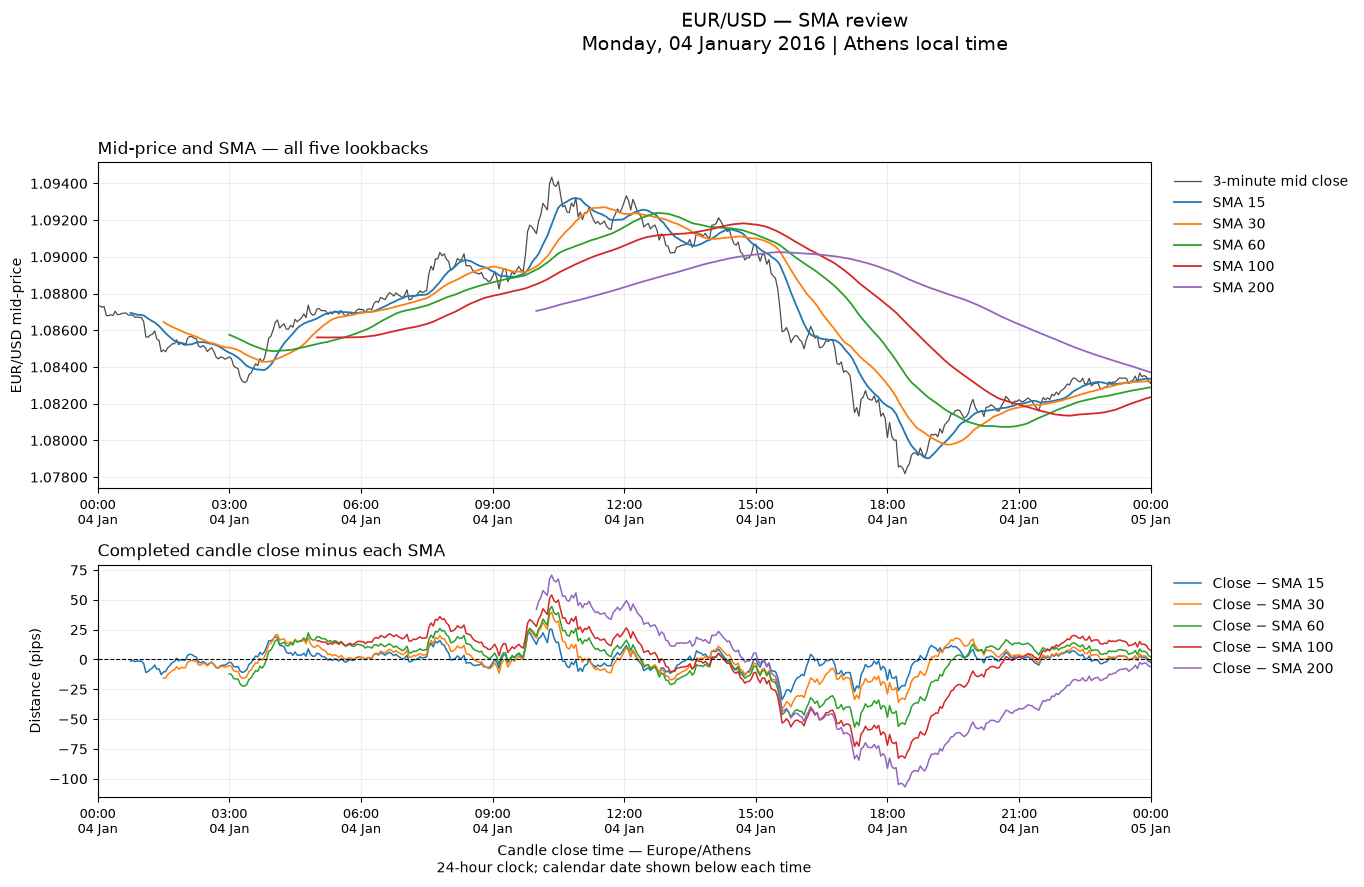

SMA periods displayed: [15, 30, 60, 100, 200]
Saved: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\figures\sampling\sampling_02_v1\first_day_moving_averages.png


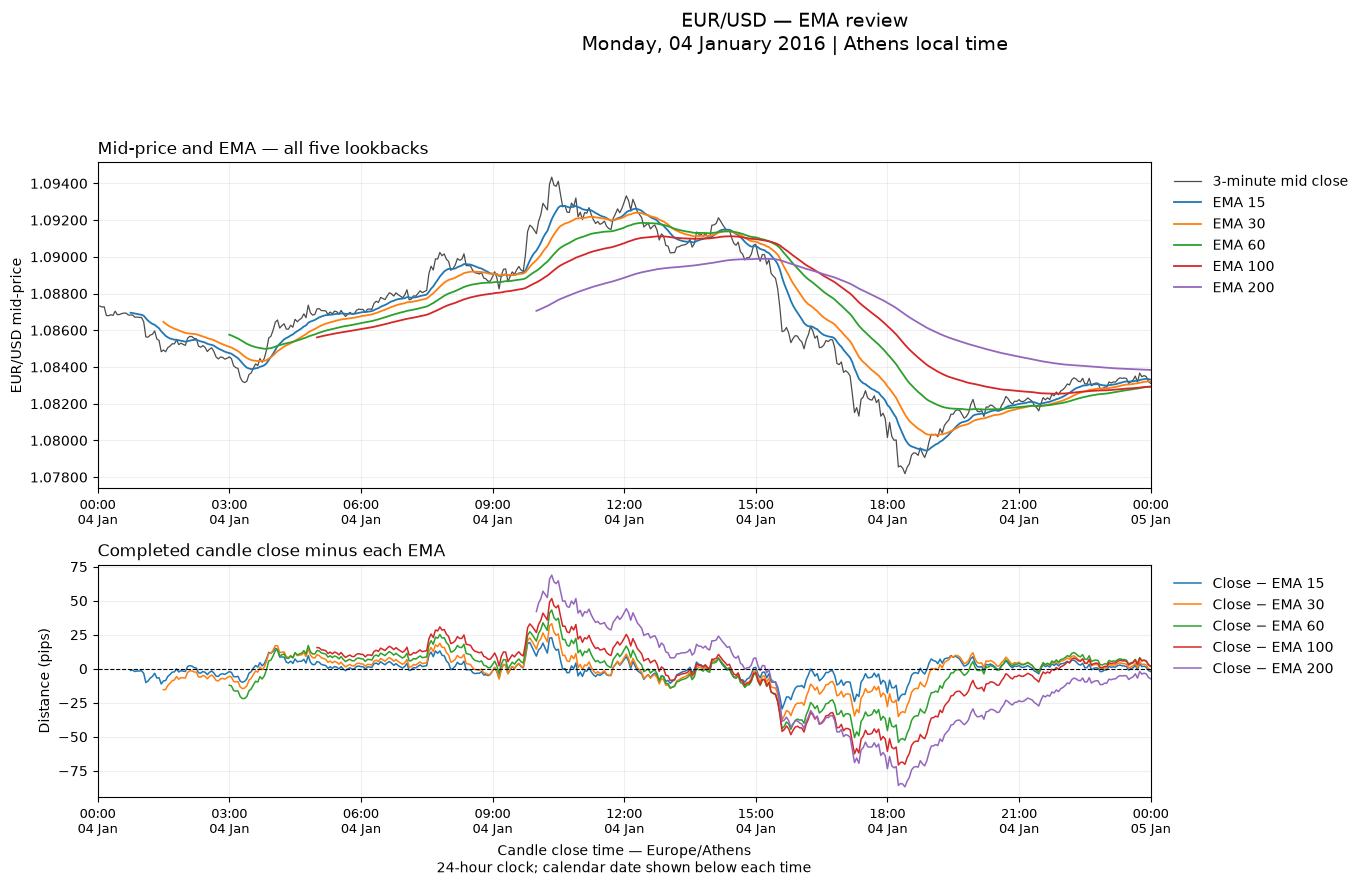

EMA periods displayed: [15, 30, 60, 100, 200]
Saved: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\figures\sampling\sampling_02_v1\first_day_ema_and_distances.png


In [26]:
# Display every agreed moving average.
# Use separate SMA and EMA figures to keep the charts readable.
# Show local clock time, calendar date and timezone explicitly.
# These are historical candle-close charts; availability delays remain saved.

import matplotlib.dates as mdates
from matplotlib.ticker import FormatStrFormatter

periods = list(s02.WINDOWS)
colors = {
    15: "tab:blue",
    30: "tab:orange",
    60: "tab:green",
    100: "tab:red",
    200: "tab:purple",
}

first_candle_file = COMPLETED[0]["outputs"]["candles_3min"]["path"]
saved_candles = pq.read_table(first_candle_file).to_pandas(
    types_mapper=pd.ArrowDtype
)

required_columns = [
    column
    for kind in ("sma", "ema")
    for n in periods
    for column in (
        f"{kind}_{n}",
        f"close_minus_{kind}_{n}_pips",
    )
]
missing_columns = [
    column for column in required_columns
    if column not in saved_candles.columns
]
assert not missing_columns, f"Missing indicator columns: {missing_columns}"

first_day = pd.Timestamp(
    FIRST_NS, unit="ns", tz="UTC"
).tz_convert("Europe/Athens").normalize()

next_day = first_day + pd.DateOffset(days=1)
display_timezone = first_day.tzinfo

# Select candles formed during the first available calendar day.
preview = saved_candles.loc[
    saved_candles["ma_eligible"]
    & (saved_candles["candle_start_ns"] >= int(first_day.value))
    & (saved_candles["candle_start_ns"] < int(next_day.value))
].copy()

assert not preview.empty, "No completed candles available for this day."

preview_time = pd.to_datetime(
    preview["candle_end_ns"].astype("Int64"),
    unit="ns",
    utc=True,
).dt.tz_convert("Europe/Athens")

# Keep the original filename for compatibility with Cell 17.
figure_path = FIGURES / "first_day_moving_averages.png"
figure_paths = {
    "sma": figure_path,
    "ema": FIGURES / "first_day_ema_and_distances.png",
}

date_label = first_day.strftime("%A, %d %B %Y")

for kind in ("sma", "ema"):
    name = kind.upper()

    fig, axes = plt.subplots(
        2, 1,
        figsize=(16, 9),
        sharex=True,
        gridspec_kw={"height_ratios": [1.4, 1]},
    )

    axes[0].plot(
        preview_time,
        preview["close_mid"].to_numpy(dtype=float, na_value=np.nan),
        color="black",
        linewidth=0.9,
        alpha=0.7,
        label="3-minute mid close",
    )

    for n in periods:
        axes[0].plot(
            preview_time,
            preview[f"{kind}_{n}"].to_numpy(
                dtype=float, na_value=np.nan
            ),
            color=colors[n],
            linewidth=1.3,
            label=f"{name} {n}",
        )

        axes[1].plot(
            preview_time,
            preview[f"close_minus_{kind}_{n}_pips"].to_numpy(
                dtype=float, na_value=np.nan
            ),
            color=colors[n],
            linewidth=1.1,
            label=f"Close − {name} {n}",
        )

    axes[0].set_title(
        f"Mid-price and {name} — all five lookbacks",
        loc="left",
    )
    axes[0].set_ylabel("EUR/USD mid-price")
    axes[0].yaxis.set_major_formatter(
        FormatStrFormatter("%.5f")
    )

    axes[1].set_title(
        f"Completed candle close minus each {name}",
        loc="left",
    )
    axes[1].axhline(
        0, color="black", linewidth=0.8, linestyle="--"
    )
    axes[1].set_ylabel("Distance (pips)")
    axes[1].set_xlabel(
        "Candle close time — Europe/Athens\n"
        "24-hour clock; calendar date shown below each time"
    )

    for ax in axes:
        ax.set_xlim(
            first_day.to_pydatetime(),
            next_day.to_pydatetime(),
        )
        ax.xaxis.set_major_locator(
            mdates.HourLocator(
                byhour=list(range(0, 24, 3)),
                tz=display_timezone,
            )
        )
        ax.xaxis.set_major_formatter(
            mdates.DateFormatter(
                "%H:%M\n%d %b",
                tz=display_timezone,
            )
        )
        ax.tick_params(
            axis="x", labelbottom=True, labelsize=9
        )
        ax.grid(True, alpha=0.2)
        ax.legend(
            loc="upper left",
            bbox_to_anchor=(1.01, 1),
            frameon=False,
        )

    fig.suptitle(
        f"EUR/USD — {name} review\n"
        f"{date_label} | Athens local time",
        fontsize=14,
    )
    fig.tight_layout(rect=(0, 0, 0.86, 0.92))

    fig.savefig(
        figure_paths[kind],
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

    print(f"{name} periods displayed:", periods)
    print("Saved:", figure_paths[kind])

In [28]:
# Record agreed decisions and implementation progress.
# This records machine execution only after the preceding cells pass.
# Human review of Notebook 02 remains pending.
# Existing accepted ETL outputs are not invalidated.

assert SYNTHETIC_CHECKS_PASSED
assert CHECKS.drop(columns="year_month").eq(0).all().all()

scope_text = (
    "full available history"
    if FULL_HISTORY_COMPLETE
    else f"prefix through {processed_labels[-1]}"
)

decision_text = f"""
## Notebook 02 — {RUN_ID}

This section records the agreed Notebook 02 definitions.
It extends feature-input scope without changing accepted Notebook 01 files.

- Decision: form fixed, clock-aligned three-minute mid OHLC candles from
  every real and eligible interpolated observation.
  Rationale: preserve available intraperiod highs and lows.
  Component: candles.
  Status: agreed.

- Decision: retain a separate clock-aligned ten-second sampled table,
  using backward lookup from the reconstructed history.
  Rationale: provide a regular research grid without replacing tick OHLC.
  Component: sampling.
  Status: agreed.

- Decision: use all-hours prices for candle and moving-average history.
  Rationale: project-excluded hours still contain useful observed prices.
  Component: candle and MA input scope.
  Status: agreed.

- Decision: interpolate actual real-anchor intervals of at most 300 seconds,
  including exactly 300 seconds; synthetic timestamps remain A+10 seconds.
  Rationale: preserve the agreed short-gap reconstruction.
  Component: interpolation.
  Status: agreed.

- Decision: allow wholly interpolated candles with anchors outside their window.
  Rationale: the 300-second eligibility rule takes precedence.
  Component: candles and later analytical inputs.
  Status: agreed; retain interpolation flags.

- Decision: never fill intervals longer than 300 seconds.
  Rationale: preserve missing periods rather than inventing prices.
  Component: missing data.
  Status: agreed.

- Decision: SMA and EMA use 15, 30, 60, 100 and 200 populated completed closes.
  Rationale: agreed trend measurements.
  Component: indicators.
  Status: agreed.

- Decision: retain MA history across every break; empty windows do not count.
  Rationale: continue the observed candle sequence after reopening.
  Component: indicator continuity.
  Status: agreed; supersedes the earlier proposed dead-zone reset.

- Decision: seed each EMA from its first N-candle SMA and use alpha=2/(N+1).
  Rationale: transparent initialization with a full lookback.
  Component: EMA.
  Status: agreed implementation.

- Decision: record close-minus-average distances in EURUSD pips.
  Rationale: measure position relative to historical price averages.
  Component: indicators.
  Status: agreed; trading interpretation remains for later design.

- Decision: retain exclusion and long-gap-overlap flags separately.
  Rationale: MA history uses all hours while experiment scope remains visible.
  Component: output interface.
  Status: agreed.

- Implementation: publication conservatively resolves the trailing real interval,
  using B or the first nanosecond beyond the 300-second limit.
  Indicator rows inherit prior dependencies using exact integer nanoseconds.
  Component: information availability.
  Status: correctness rule; machine checks supplied.

- Execution scope: {scope_text}.
- Machine checks for the processed prefix: passed.
- Human review: pending.
- Fingerprint: `{FINGERPRINT}`.
- No volatility estimator, entropy estimator or trading policy is selected here.
"""

s02.write_section(
    ROOT / "docs" / "design_decisions.md",
    f"notebook-02-{RUN_ID}",
    decision_text,
)

contribution_text = f"""
## Notebook 02 — {RUN_ID}

Raymond Fendi:
- Selected three-minute mid-price candles and a separate ten-second grid.
- Selected SMA and EMA periods 15, 30, 60, 100 and 200.
- Required MA history to persist across all market-data breaks.
- Required all-hours prices to contribute to MA history.
- Confirmed the <=300-second interpolation rule takes precedence for
  wholly interpolated candles.
- Selected OHLC construction from every eligible observation.
- Accepted delayed reconstructed sampling with explicit availability.
- Requested separate close-to-average distance columns.

OpenAI Codex:
- Prepared Notebook 02, its shared helper, inline validation and documentation.
- Preserved the distinction between event time and information availability.
- Supplied synthetic anchor, month-boundary and indicator-continuity checks.
- Identified interpolation as an assumed path whose statistical effects
  require review during volatility and entropy design.

Execution scope: {scope_text}.
Processed-prefix machine checks passed when this documentation cell ran.
Raymond's review of Notebook 02 execution outputs remains pending.
Trading results remain pending simulation and evaluation.
"""

s02.write_section(
    ROOT / "CONTRIBUTIONS.md",
    f"notebook-02-{RUN_ID}",
    contribution_text,
)

readme_text = f"""
## Notebook 02 progress

- All-hours quote reconstruction, ten-second sampling, three-minute candles,
  SMA/EMA and close-to-average distances are implemented.
- Execution scope: {scope_text}.
- Processed-prefix machine checks passed; human output review is pending.
- Notebook 01's accepted files remain unchanged.
- Interpolated observations are research inputs, not execution liquidity.
- Moving-average distance is a measurement, not a trading instruction.

Results pending execution and validation.
"""

s02.write_section(
    ROOT / "README.md",
    f"notebook-02-{RUN_ID}",
    readme_text,
)

project_state = f"""# Project state

- Completed and reviewed: Notebook 00, Notebook 01 and Notebook 01a.
- Accepted ETL run: `{ETL_RUN_ID}`.
- Current stage: Notebook 02 execution review.
- Notebook 02 run: `{RUN_ID}`.
- Notebook 02 execution scope: {scope_text}.
- Processed-prefix machine checks: passed.
- Full-history Notebook 02 processing complete: {FULL_HISTORY_COMPLETE}.
- Notebook 02 human review: pending.

## Locations

- Observed input quotes: `data/processed/{ETL_RUN_ID}/observed/`.
- Accepted masked analysis quotes: `data/processed/{ETL_RUN_ID}/analysis/`.
- New all-hours reconstructed quotes: `data/processed/{RUN_ID}/quotes/`.
- Ten-second samples: `data/processed/{RUN_ID}/sampled_10s/`.
- Three-minute candles and indicators: `data/processed/{RUN_ID}/candles_3min/`.
- Retrospective all-hours long gaps: `data/processed/{RUN_ID}/long_gaps/`.
- Notebook 02 reports: `reports/tables/sampling/{RUN_ID}/`.

## Outstanding matters

- Review Notebook 02 outputs before expanding processing.
- Exact historical provider closure completeness remains a documented limitation.
- Locked quotes and zero displayed sizes remain excluded from P&L inputs.
- Execution and valuation handling will be designed during accounting.
- Statistical effects of interpolation will be examined during feature design.

## Next step

Return Notebook 02's requested outputs for review.
After acceptance, extend STOP_AFTER_MONTH using the same notebook and run.

## Outputs invalidated

None from the accepted ETL.
Notebook 02 introduces a new versioned all-hours feature-input scope.
Changing this definition requires new outputs before downstream reuse.
No downstream volatility, entropy, model or simulation outputs exist yet.
"""

(ROOT / "docs" / "project_state.md").write_text(
    project_state, encoding="utf-8"
)

print("Decision, contribution, README and project-state records updated.")
print("Notebook 02 human review remains pending.")

Decision, contribution, README and project-state records updated.
Notebook 02 human review remains pending.


In [29]:
# Final execution summary.
# A prefix run is not reported as a completed full-history run.

SUMMARY = {
    "notebook": "02_sampling_candles_and_indicators.ipynb",
    "run_id": RUN_ID,
    "fingerprint": FINGERPRINT,
    "upstream_run_id": ETL_RUN_ID,
    "upstream_fingerprint": EXPECTED_ETL_FINGERPRINT,
    "mode": "full_history" if FULL_HISTORY_COMPLETE else "prefix_review",
    "available_input_months": len(METADATA),
    "processed_months": len(COMPLETED),
    "processed_through": processed_labels[-1],
    "full_history_complete": FULL_HISTORY_COMPLETE,
    "available_real_rows": int(INPUT_INVENTORY["rows"].sum()),
    "processed_real_rows": int(MONTHLY["real_rows"].sum()),
    "synthetic_rows": int(MONTHLY["synthetic_rows"].sum()),
    "all_hours_quote_rows": int(MONTHLY["quote_rows"].sum()),
    "sample_rows": int(MONTHLY["sample_rows"].sum()),
    "sample_rows_with_prices": int(MONTHLY["sample_rows_with_prices"].sum()),
    "candle_rows": int(MONTHLY["candle_rows"].sum()),
    "populated_completed_candles": int(
        MONTHLY["populated_completed_candles"].sum()
    ),
    "synthetic_only_completed_candles": int(
        MONTHLY["synthetic_only_completed_candles"].sum()
    ),
    "empty_candles": int(MONTHLY["empty_candles"].sum()),
    "all_hours_long_gap_parents": int(
        MONTHLY["all_hours_long_gap_parents"].sum()
    ),
    "ma_windows": list(s02.WINDOWS),
    "moving_averages_reset_after_breaks": False,
    "synthetic_checks_passed": SYNTHETIC_CHECKS_PASSED,
    "nonzero_machine_checks": int(
        (CHECKS.drop(columns="year_month") != 0).sum().sum()
    ),
    "processed_prefix_machine_checks_passed": True,
    "human_review": "pending",
    "source_stability_check": (
        "file size and modification time; no data content hashing"
    ),
    "wall_minutes_since_settings_cell": round(
        (time.perf_counter() - STARTED) / 60, 3
    ),
}

fx.dump_json(TABLES / "execution_summary.json", SUMMARY)
fx.dump_json(RUN / "run_state.json", {
    "fingerprint": FINGERPRINT,
    "status": (
        "full_history_processed"
        if FULL_HISTORY_COMPLETE
        else "prefix_processed"
    ),
    "processed_through": processed_labels[-1],
    "machine_checks_passed": True,
    "human_review": "pending",
    "summary": (TABLES / "execution_summary.json").relative_to(ROOT).as_posix(),
})

print("NOTEBOOK_02_EXECUTION_SUMMARY")
print(json.dumps(SUMMARY, indent=2))
print("\nReports:", TABLES)
print("Figure:", figure_path)
print("\nSTOP HERE: return the requested outputs before expanding processing.")

NOTEBOOK_02_EXECUTION_SUMMARY
{
  "notebook": "02_sampling_candles_and_indicators.ipynb",
  "run_id": "sampling_02_v1",
  "fingerprint": "ad5235dc14f854d9f26ef04dd2c1fdf846faf05cff43eb9f84afccc229628e54",
  "upstream_run_id": "etl_01_v3",
  "upstream_fingerprint": "205fc8b3f2417d6bcbff97a34f49215ca1cc5f2b89c626eed6a26cec65231902",
  "mode": "full_history",
  "available_input_months": 130,
  "processed_months": 130,
  "processed_through": "2026-10",
  "full_history_complete": true,
  "available_real_rows": 295114784,
  "processed_real_rows": 295114784,
  "synthetic_rows": 3536129,
  "all_hours_quote_rows": 298650913,
  "sample_rows": 34032599,
  "sample_rows_with_prices": 24206917,
  "candle_rows": 1890700,
  "populated_completed_candles": 1345175,
  "synthetic_only_completed_candles": 198,
  "empty_candles": 545524,
  "all_hours_long_gap_parents": 836,
  "ma_windows": [
    15,
    30,
    60,
    100,
    200
  ],
  "moving_averages_reset_after_breaks": false,
  "synthetic_checks_pass

In [30]:
# Extend the existing run to the full available history.
# January's checkpoint and outputs must remain unchanged.

required_variables = (
    "ROOT", "RUN", "RUN_ID", "fx", "s02",
    "SYNTHETIC_CHECKS_PASSED", "hashlib", "time",
)
missing_variables = [
    name for name in required_variables
    if name not in globals()
]
assert not missing_variables, (
    f"Kernel setup is missing: {missing_variables}. "
    "Run existing Cells 2–11, then run this cell again."
)

assert RUN_ID == "sampling_02_v1"
assert SYNTHETIC_CHECKS_PASSED

january_checkpoint_path = RUN / "_checkpoints" / "2016-01.json"
january_checkpoint_before = fx.load_json(january_checkpoint_path)

assert all(
    value == 0
    for value in january_checkpoint_before["checks"].values()
)

JANUARY_CHECKPOINT_SHA256 = hashlib.sha256(
    january_checkpoint_path.read_bytes()
).hexdigest()
JANUARY_REVIEWED_FINGERPRINT = january_checkpoint_before["fingerprint"]

STOP_AFTER_MONTH = None
STARTED = time.perf_counter()

print("Full-history target selected.")
print("Keep RUN_ID:", RUN_ID)
print("Next: run existing Cell 8.")
print("Confirm it reports 130 target months.")
print("Then run existing Cells 12–17, followed by Cell 20 below.")

Full-history target selected.
Keep RUN_ID: sampling_02_v1
Next: run existing Cell 8.
Confirm it reports 130 target months.
Then run existing Cells 12–17, followed by Cell 20 below.


In [31]:
# Run AFTER existing Cells 12–17 finish successfully.
# Check complete coverage, continuous MA state and January preservation.

assert FULL_HISTORY_COMPLETE
assert SUMMARY["mode"] == "full_history"
assert SUMMARY["fingerprint"] == JANUARY_REVIEWED_FINGERPRINT
assert SUMMARY["nonzero_machine_checks"] == 0

expected_labels = [meta["year_month"] for meta in METADATA]

FULL_HISTORY_CHECKS = {
    "all_130_months_processed": (
        len(COMPLETED) == len(METADATA) == 130
    ),
    "months_in_exact_input_order": (
        processed_labels == expected_labels
    ),
    "coverage_starts_2016_01": (
        processed_labels[0] == "2016-01"
    ),
    "coverage_ends_2026_10": (
        processed_labels[-1] == "2026-10"
    ),
    "all_real_rows_preserved": (
        int(MONTHLY["real_rows"].sum())
        == int(INPUT_INVENTORY["rows"].sum())
        == 295_114_784
    ),
    "every_monthly_check_zero": bool(
        CHECKS.drop(columns="year_month").eq(0).all().all()
    ),
}

# Check the complete clock grids, including empty intervals.
expected_sample_rows = (
    LAST_NS // s02.STEP
    - (FIRST_NS + s02.STEP - 1) // s02.STEP
    + 1
)
expected_candle_rows = (
    LAST_NS // s02.BAR
    - FIRST_NS // s02.BAR
    + 1
)

FULL_HISTORY_CHECKS["complete_10_second_grid"] = (
    int(MONTHLY["sample_rows"].sum()) == expected_sample_rows
)
FULL_HISTORY_CHECKS["complete_3_minute_clock"] = (
    int(MONTHLY["candle_rows"].sum()) == expected_candle_rows
)

# Verify accumulated candle counts and retained MA state across all months.
accumulated_candles = 0
previous_dependency = None
previous_candle_end = None

for done in COMPLETED:
    accumulated_candles += int(
        done["summary"]["populated_completed_candles"]
    )
    saved_state = done["state_after"]

    assert saved_state["valid_candles"] == accumulated_candles
    assert len(saved_state["tail_closes"]) == min(
        accumulated_candles, 199
    )
    assert np.isfinite(
        np.asarray(saved_state["tail_closes"], dtype=float)
    ).all()

    for n in s02.WINDOWS:
        value = saved_state["ema_values"][str(n)]
        if accumulated_candles >= n:
            assert value is not None and np.isfinite(value)
        else:
            assert value is None

    if accumulated_candles:
        dependency = saved_state["dependency_available_ns"]
        candle_end = saved_state["last_candle_end_ns"]

        assert dependency >= candle_end

        if previous_dependency is not None:
            assert dependency >= previous_dependency
            assert candle_end >= previous_candle_end

        previous_dependency = dependency
        previous_candle_end = candle_end

FULL_HISTORY_CHECKS["continuous_ma_state"] = True
FULL_HISTORY_CHECKS["ma_count_matches_all_valid_candles"] = (
    accumulated_candles
    == int(MONTHLY["populated_completed_candles"].sum())
)

# January must have been reused without changing its checkpoint or data.
FULL_HISTORY_CHECKS["january_checkpoint_unchanged"] = (
    hashlib.sha256(
        january_checkpoint_path.read_bytes()
    ).hexdigest()
    == JANUARY_CHECKPOINT_SHA256
)

january_outputs_unchanged = all(
    s02.file_info(output["path"]) == output
    for output in january_checkpoint_before["outputs"].values()
)
FULL_HISTORY_CHECKS["january_outputs_unchanged"] = (
    january_outputs_unchanged
)

failed_checks = [
    name for name, passed in FULL_HISTORY_CHECKS.items()
    if not passed
]
assert not failed_checks, f"Full-history checks failed: {failed_checks}"

fx.dump_json(TABLES / "full_history_completion_checks.json", {
    "run_id": RUN_ID,
    "fingerprint": FINGERPRINT,
    "checks": FULL_HISTORY_CHECKS,
    "machine_checks_passed": True,
    "human_review": "pending",
})

display(pd.Series(
    FULL_HISTORY_CHECKS,
    name="passed",
).to_frame())

print("FULL_HISTORY_COMPLETION_CHECKS_PASSED")
print("Reports:", TABLES)
print("Tell me 'full-history outputs are ready' for direct review.")

,passed
all_130_months_processed,True
months_in_exact_input_order,True
coverage_starts_2016_01,True
coverage_ends_2026_10,True
all_real_rows_preserved,True
every_monthly_check_zero,True
complete_10_second_grid,True
complete_3_minute_clock,True
continuous_ma_state,True
ma_count_matches_all_valid_candles,True


FULL_HISTORY_COMPLETION_CHECKS_PASSED
Reports: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\tables\sampling\sampling_02_v1
Tell me 'full-history outputs are ready' for direct review.
